# Information-Theoretic Learning (ITL): Five Visual Experiments

**Colab-ready executable notebook** based on the kernel-information-potential framework in José C. Principe, *Information Theoretic Learning: Rényi's Entropy and Kernel Perspectives* (2010), especially Ch. 2 §§2.3, 2.6, 2.8–2.10; Ch. 6 §6.6; and Ch. 7 §7.6.

**Experiments**

1. Gaussian potential fields in 1D and 2D, varying bandwidth.
2. Information-force vector fields, gradient checks, and connection to mean shift.
3. Particle attraction (minimize quadratic Rényi entropy) and repulsion (maximize it).
4. Distribution matching by minimizing quadratic Euclidean divergence, and comparisons to Cauchy–Schwarz divergence.
5. Quadratic mutual-information maximization for two labeled classes: learn a 1D projection that preserves class information.

The book motivates the **information potential** $V_2=\int p(x)^2\,dx$, the **information force**, and divergences built from kernel pair interactions. This notebook provides *illustrative implementations and experiment choices*, not reproduced book code or numerical results.

All optimization examples are didactic; they should not be interpreted as general performance benchmarks. Gaussian bandwidth and data dimension significantly influence results.

## Setup and notation

We distinguish the density estimator bandwidth $\sigma$ from the **effective interaction bandwidth** $h=\sqrt{2}\sigma$:

$$\widehat p_\sigma(x)=\frac1N\sum_i G_\sigma(x-x_i),\qquad
\widehat V_2=\frac1{N^2}\sum_{i,j}G_h(x_i-x_j),\quad h=\sqrt2\sigma.$$

$$G_h(z)=(2\pi h^2)^{-d/2}\exp[-\|z\|^2/(2h^2)],\qquad \widehat H_2=-\log\widehat V_2.$$

We use NumPy / Matplotlib for visualizations, and PyTorch automatic differentiation for optimizers. Colab's standard environment usually provides all three.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from matplotlib.colors import LogNorm

np.random.seed(7)
torch.manual_seed(7)
print('NumPy:', np.__version__, '| Torch:', torch.__version__)

plt.rcParams.update({'figure.figsize': (8, 4.7), 'figure.dpi': 110})

def gaussian_np(delta, h, normalized=True):
    """Isotropic Gaussian evaluated on vectors (..., d)."""
    d = delta.shape[-1]
    pref = (2*np.pi*h*h)**(-d/2) if normalized else 1.0
    return pref * np.exp(-np.sum(delta**2, axis=-1)/(2*h*h))

def pair_kernel_np(X, Y, h, normalized=True):
    X = np.atleast_2d(X)
    Y = np.atleast_2d(Y)
    return gaussian_np(X[:,None,:] - Y[None,:,:], h, normalized)

def field_and_force_np(query, particles, h, normalized=True):
    """Phi(x)=mean_i G_h(x-x_i), F(x)=grad_x Phi(x), evaluated at query points."""
    query = np.atleast_2d(query)
    particles = np.atleast_2d(particles)
    diff = query[:,None,:] - particles[None,:,:]
    K = gaussian_np(diff, h, normalized)
    phi = K.mean(axis=1)
    F = -(K[:,:,None]*diff).mean(axis=1)/(h*h)
    return phi, F

def gaussian_torch_diff(diff, h):
    d = diff.shape[-1]
    return (2*torch.pi*h*h)**(-d/2) * torch.exp(-torch.sum(diff**2, dim=-1)/(2*h*h))

def pair_kernel_torch(A, B, h):
    return gaussian_torch_diff(A[:,None,:]-B[None,:,:], h)

NumPy: 2.3.5 | Torch: 2.10.0+cpu


## Experiment 1 — Gaussian potential fields (one or many particles)

For fixed particles $x_i$, define the local field

$$\Phi(x)=\frac1N\sum_{i=1}^N G_h(x-x_i).$$

A smaller $h$ creates narrow peaks; a larger $h$ produces a smoother, broader field. **This is a local field**—not the scalar global information potential $\widehat V_2=N^{-1}\sum_j\Phi(x_j)$.

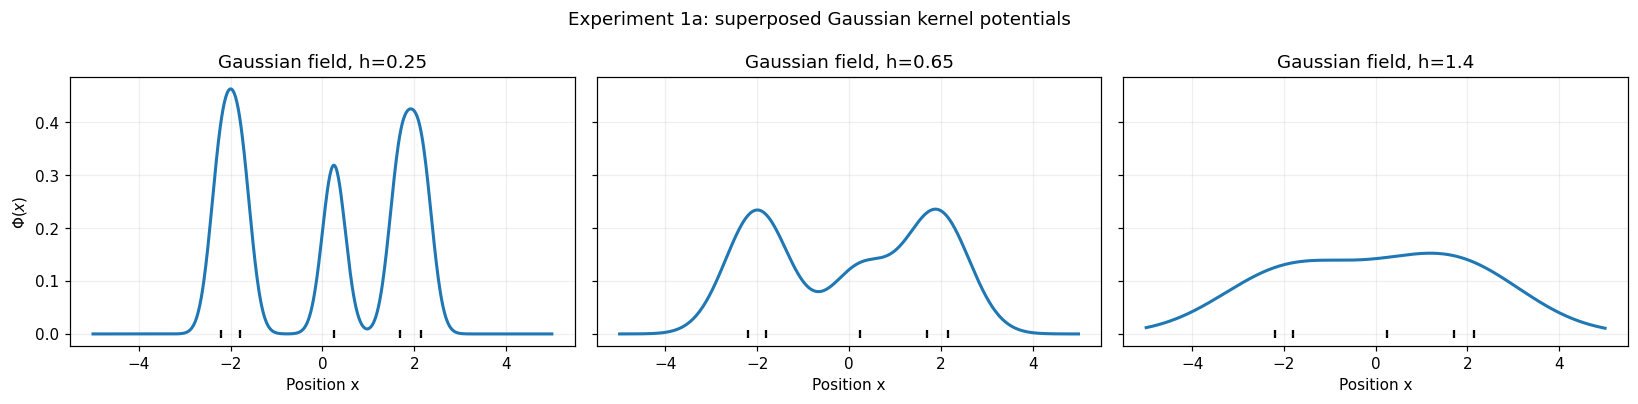

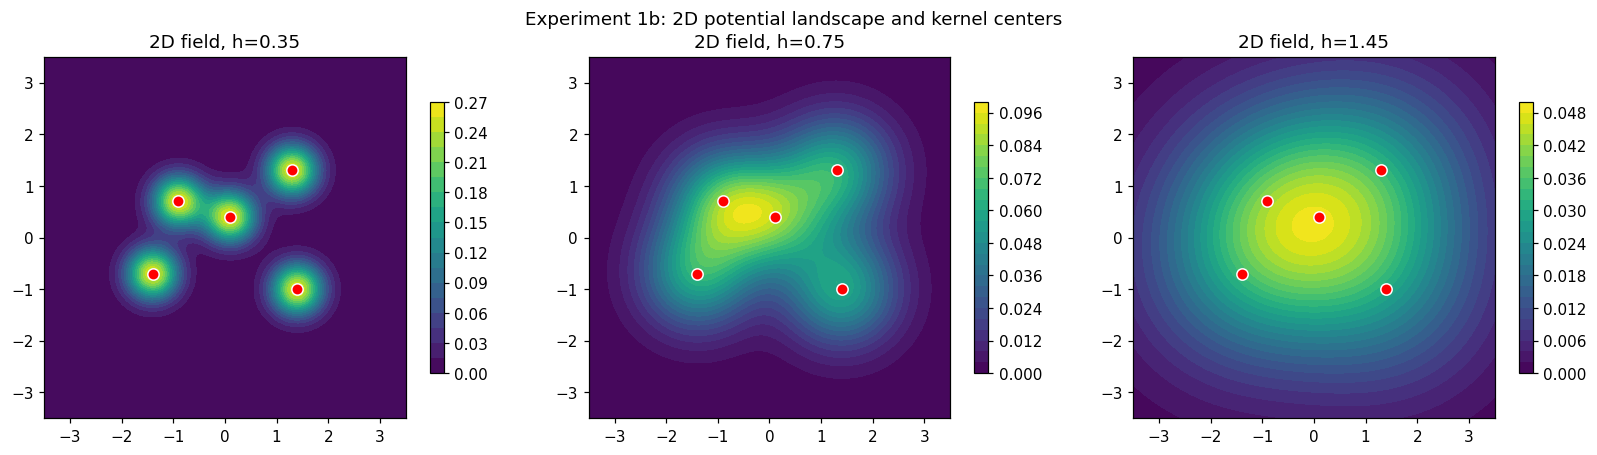

In [2]:
particles_1d = np.array([[-2.2], [-1.8], [0.25], [1.7], [2.15]])
xaxis = np.linspace(-5,5,700)[:,None]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.7), sharey=True)
for ax,h in zip(axes,[0.25,0.65,1.4]):
    phi,_ = field_and_force_np(xaxis, particles_1d, h)
    ax.plot(xaxis.ravel(), phi, lw=2)
    ax.scatter(particles_1d.ravel(), np.zeros(len(particles_1d)), c='k', s=27, marker='|', label='particles')
    ax.set_title(f'Gaussian field, h={h}')
    ax.set_xlabel('Position x'); ax.grid(alpha=.2)
axes[0].set_ylabel(r'$\Phi(x)$')
plt.suptitle('Experiment 1a: superposed Gaussian kernel potentials')
plt.tight_layout(); plt.show()

particles_2d = np.array([[-1.4,-0.7], [-.9, .7], [.1,.4], [1.3,1.3], [1.4,-1.0]])
grid_axis = np.linspace(-3.5,3.5,115)
XX, YY = np.meshgrid(grid_axis, grid_axis)
query = np.stack([XX.ravel(), YY.ravel()], axis=-1)
fig, axes = plt.subplots(1,3,figsize=(15,4))
for ax,h in zip(axes,[.35,.75,1.45]):
    phi,_ = field_and_force_np(query,particles_2d,h)
    artist = ax.contourf(XX,YY,phi.reshape(XX.shape),levels=24,cmap='viridis')
    ax.scatter(*particles_2d.T,c='red',edgecolors='white',s=55,zorder=3)
    ax.set_aspect('equal'); ax.set_title(f'2D field, h={h}')
    fig.colorbar(artist,ax=ax,shrink=.75)
plt.suptitle('Experiment 1b: 2D potential landscape and kernel centers')
plt.tight_layout(); plt.show()

## Experiment 2 — Force fields and analytic versus numerical gradients

The **information force** in the book's field-gradient convention is

$$\mathbf F(x)=\nabla_x\Phi(x)=\frac1{Nh^2}\sum_iG_h(x-x_i)(x_i-x).$$

This points uphill in the Gaussian potential landscape. It is **not** the negative gradient of a mechanical potential energy. The **score** $\nabla\log\Phi(x)=\mathbf F(x)/\Phi(x)$ is related to the mean-shift displacement by $m(x)-x=h^2\nabla\log\Phi(x)$.

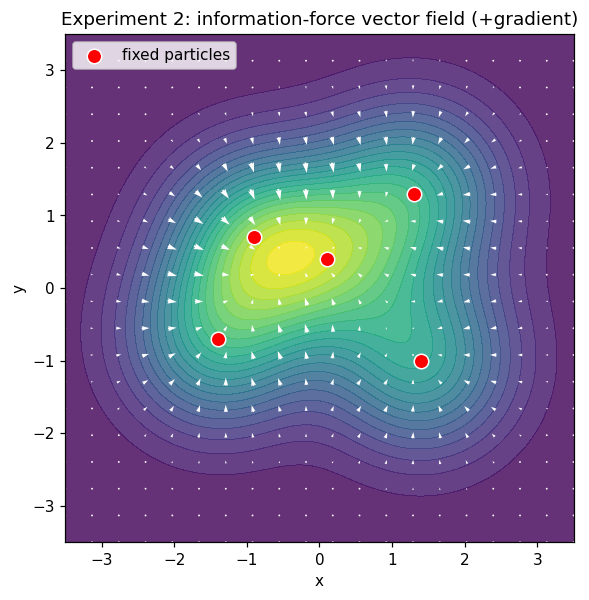

Analytic local force: [-0.00832751  0.02821155]
Finite-difference gradient: [-0.00832751  0.02821155]
Maximum absolute error: 8.0210837971606e-13
Mean-shift displacement: [-0.15986633  0.24185833]
h^2 * score: [-0.15986633  0.24185833]


In [3]:
h=.85
phi, force = field_and_force_np(query,particles_2d,h)
step=6
Xs,Ys = XX[::step,::step],YY[::step,::step]
Fs = force.reshape(*XX.shape,2)[::step,::step,:]
fig,ax=plt.subplots(figsize=(7,6))
ax.contourf(XX,YY,phi.reshape(XX.shape),24,cmap='viridis',alpha=.83)
ax.quiver(Xs,Ys,Fs[:,:,0],Fs[:,:,1],color='white',pivot='mid',scale=2.5,width=.004)
ax.scatter(*particles_2d.T,c='red',edgecolors='white',s=90,zorder=5,label='fixed particles')
ax.set(title='Experiment 2: information-force vector field (+gradient)',xlabel='x',ylabel='y',aspect='equal')
ax.legend(loc='upper left');plt.show()

# Finite-difference verification at an arbitrary query point
z=np.array([[.45,-.28]])
phi0,f_analytic=field_and_force_np(z,particles_2d,h)
eps=1e-5
f_numeric=np.zeros(2)
for dimension in range(2):
    unit=np.zeros((1,2));unit[0,dimension]=eps
    plus=field_and_force_np(z+unit,particles_2d,h)[0][0]
    minus=field_and_force_np(z-unit,particles_2d,h)[0][0]
    f_numeric[dimension]=(plus-minus)/(2*eps)
print('Analytic local force:',f_analytic[0])
print('Finite-difference gradient:',f_numeric)
print('Maximum absolute error:',np.max(np.abs(f_analytic[0]-f_numeric)))
assert np.allclose(f_analytic[0],f_numeric,rtol=1e-6,atol=1e-7)

# One mean-shift update and the exact score relationship
z=np.array([[.2,.1]])
weights=pair_kernel_np(z,particles_2d,h).ravel()
mean_shift=(weights[:,None]*particles_2d).sum(axis=0)/weights.sum()-z.ravel()
ph,fo=field_and_force_np(z,particles_2d,h)
print('Mean-shift displacement:',mean_shift)
print('h^2 * score:',h*h*fo.ravel()/ph[0])

## Experiment 3 — Movable particles: attraction and repulsion

For a **moving** sample configuration $X=(x_1,\ldots,x_N)$,

$$V_2(X)=\frac1{N^2}\sum_{i,j}G_h(x_i-x_j),\qquad
\nabla_{x_k}V_2=\frac{2}{N^2h^2}\sum_jG_h(x_k-x_j)(x_j-x_k).$$

The $2/N$ difference from the **local** field force matters: $\nabla_{x_k}V_2=(2/N)\mathbf F(x_k)$, where the field includes the movable particles. Also $\nabla_{x_k}H_2=-\nabla_{x_k}V_2/V_2$.

- **Attraction**: gradient ascent on $V_2$ (equivalently descent on $H_2$).
- **Repulsion**: gradient descent on $V_2$ (equivalently ascent on $H_2$).

We use a prescribed step size rather than a physical-time model. Maximizing differential entropy without spatial constraints can push samples apart indefinitely.

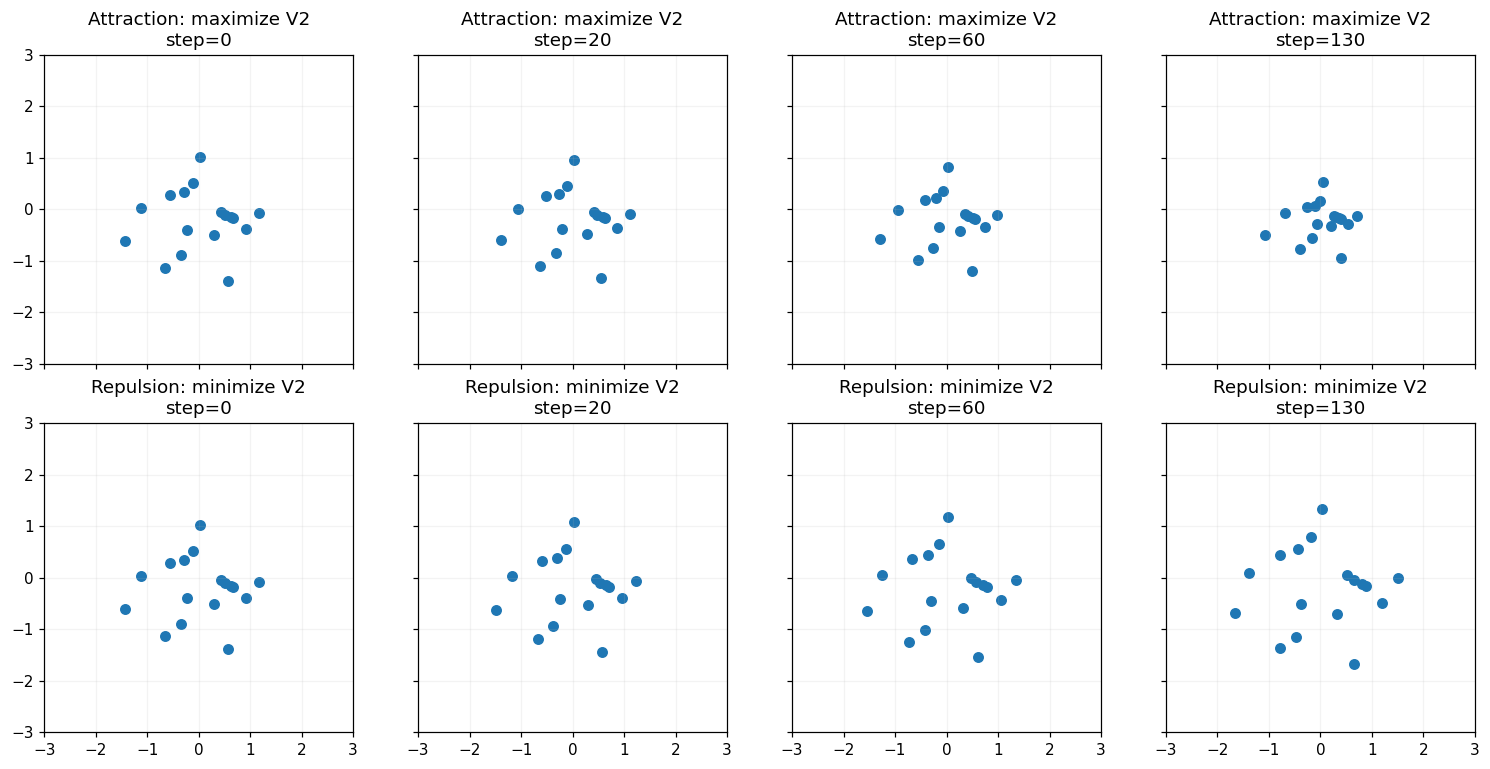

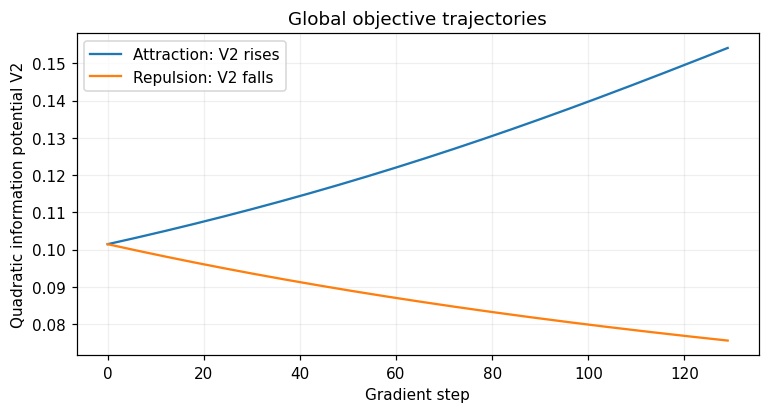

Global V2 gradient analytic: 0.0030670206689313293 finite difference: 0.0030670206693783615


In [4]:
def V2_and_gradient_numpy(X,h):
    diff=X[:,None,:]-X[None,:,:]
    K=gaussian_np(diff,h)
    V=K.mean()
    grad=-(2/(len(X)**2*h*h)) * np.sum(K[:,:,None]*diff,axis=1)
    return V,grad

rng=np.random.default_rng(11)
start=rng.normal(0,.75,size=(17,2))
h=.85

def evolve_particles(start, sign, steps=130, lr=.32):
    X=start.copy(); history=[X.copy()]; potentials=[]
    for t in range(steps):
        V,grad=V2_and_gradient_numpy(X,h)
        potentials.append(V)
        X=X+sign*lr*grad
        history.append(X.copy())
    return np.asarray(history),np.asarray(potentials)

attr,va=evolve_particles(start,+1)
rep,vr=evolve_particles(start,-1)
fig,axs=plt.subplots(2,4,figsize=(14,7),sharex=True,sharey=True)
for row,(trajectory,name) in enumerate([(attr,'Attraction: maximize V2'),(rep,'Repulsion: minimize V2')]):
    for col,t in enumerate([0,20,60,130]):
        ax=axs[row,col];ax.scatter(*trajectory[t].T,s=38)
        ax.set(xlim=(-3,3),ylim=(-3,3),aspect='equal',title=f'{name}\nstep={t}')
        ax.grid(alpha=.15)
plt.tight_layout();plt.show()

fig,ax=plt.subplots(figsize=(8,3.8))
ax.plot(va,label='Attraction: V2 rises')
ax.plot(vr,label='Repulsion: V2 falls')
ax.set(xlabel='Gradient step',ylabel='Quadratic information potential V2',title='Global objective trajectories')
ax.grid(alpha=.2);ax.legend();plt.show()

V,g=V2_and_gradient_numpy(start,h)
E=np.zeros_like(start);E[2,1]=1e-5
num=(V2_and_gradient_numpy(start+E,h)[0]-V2_and_gradient_numpy(start-E,h)[0])/(2e-5)
print('Global V2 gradient analytic:',g[2,1], 'finite difference:',num)
assert abs(g[2,1]-num)<1e-7

## Experiment 4 — Distribution matching using ITL divergence

Let $p$ be a fixed target distribution, with samples $X$, and $q_\theta$ an adaptive distribution whose samples $Y$ are optimized. Using equal Gaussian KDE bandwidth $\sigma$ and interaction bandwidth $h=\sqrt2\sigma$,

$$V_p=\frac1{N^2}\sum_{ij}G_h(x_i-x_j),\quad V_q=\frac1{M^2}\sum_{ij}G_h(y_i-y_j),\quad
V_c=\frac1{NM}\sum_{ij}G_h(x_i-y_j).$$

$$D_{\rm ED}(p,q)=V_p+V_q-2V_c,\qquad D_{\rm CS}(p,q)=\log\frac{V_pV_q}{V_c^2}.$$

For the squared Euclidean divergence, gradient descent makes $Y$ **repel itself** (from $V_q$) while being **attracted toward** $X$ (from $-2V_c$). The exact relative strengths and outcome depend on bandwidth and initialization. We use PyTorch autodiff to verify that optimizing these kernel sums changes the sample configuration as predicted.

**Note:** the squared $L^2$ divergence estimated from matching Gaussian KDEs equals a Gaussian-kernel squared MMD with kernel bandwidth $h$; this does not make every ITL divergence equal to MMD.

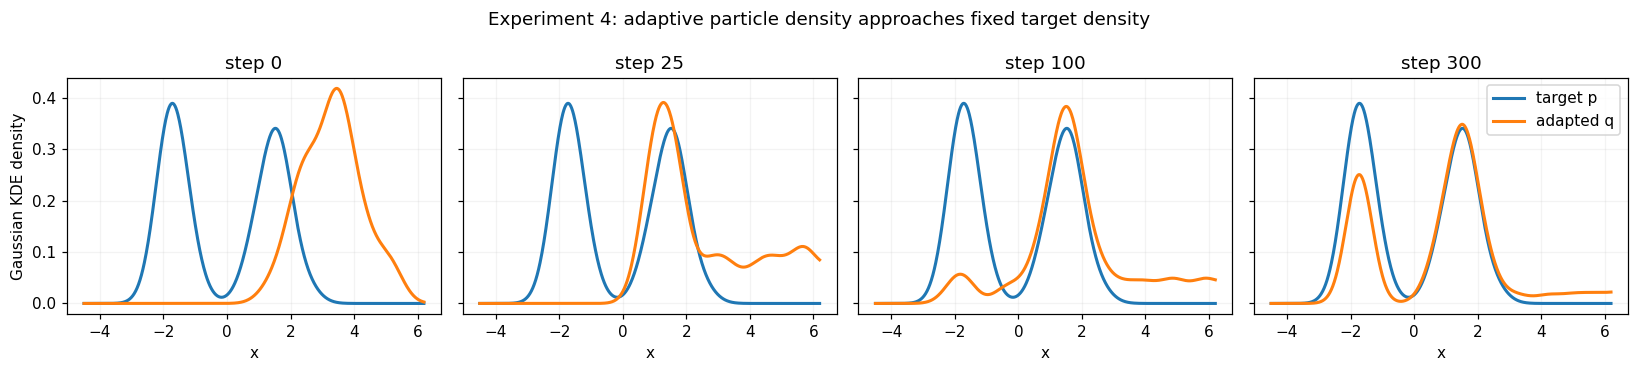

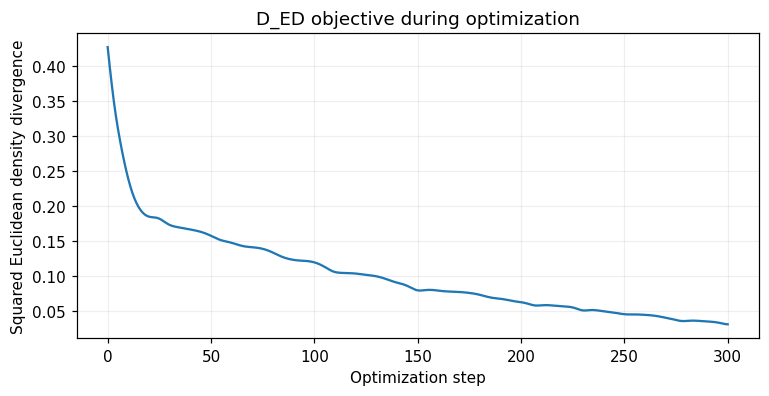

Initial ED divergence: 0.4268809499774059
Final ED divergence: 0.030438207910311488
Initial CS divergence: 3.1728065031365205
Final CS divergence: 0.11277212962034389


In [5]:
def potentials_torch(X,Y,h):
    Vp=pair_kernel_torch(X,X,h).mean()
    Vq=pair_kernel_torch(Y,Y,h).mean()
    Vc=pair_kernel_torch(X,Y,h).mean()
    return Vp,Vq,Vc

def divergence_torch(X,Y,h,kind='ED'):
    Vp,Vq,Vc=potentials_torch(X,Y,h)
    if kind=='ED': return Vp+Vq-2*Vc
    if kind=='CS': return torch.log(Vp)+torch.log(Vq)-2*torch.log(Vc)
    raise ValueError(kind)

rng=np.random.default_rng(30)
target_np=np.r_[rng.normal(-1.7,.33,35),rng.normal(1.5,.43,35)][:,None]
source_np=rng.normal(0,.9,size=(65,1))+3.2
X=torch.tensor(target_np,dtype=torch.float64)
Y=torch.tensor(source_np,dtype=torch.float64,requires_grad=True)
h=.58
opt=torch.optim.Adam([Y],lr=.075)
losses=[];snaps={0:source_np.copy()}
for t in range(301):
    opt.zero_grad()
    loss=divergence_torch(X,Y,h,'ED')
    losses.append(loss.item())
    if t in [25,100,300]: snaps[t]=Y.detach().numpy().copy()
    if t<300:
        loss.backward();opt.step()

fig,axes=plt.subplots(1,4,figsize=(15,3.4),sharex=True,sharey=True)
axis=np.linspace(-4.5,6.2,700)[:,None]
def kde_np(axis,data,band):
    return pair_kernel_np(axis,data,band).mean(axis=1)
for ax,(step,sample) in zip(axes,snaps.items()):
    ax.plot(axis.ravel(),kde_np(axis,target_np,h/np.sqrt(2)),label='target p',lw=2)
    ax.plot(axis.ravel(),kde_np(axis,sample,h/np.sqrt(2)),label='adapted q',lw=2)
    ax.set(title=f'step {step}',xlabel='x')
    ax.grid(alpha=.15)
axes[0].set_ylabel('Gaussian KDE density')
axes[-1].legend()
plt.suptitle('Experiment 4: adaptive particle density approaches fixed target density')
plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(8,3.6))
ax.plot(losses)
ax.set(xlabel='Optimization step',ylabel='Squared Euclidean density divergence',title='D_ED objective during optimization')
ax.grid(alpha=.2);plt.show()
with torch.no_grad():
    print('Initial ED divergence:',float(divergence_torch(X,torch.tensor(source_np),h,'ED')))
    print('Final ED divergence:',float(divergence_torch(X,Y,h,'ED')))
    print('Initial CS divergence:',float(divergence_torch(X,torch.tensor(source_np),h,'CS')))
    print('Final CS divergence:',float(divergence_torch(X,Y,h,'CS')))

### Closed-form Gaussian divergence versus mean separation

If $p=\mathcal N(0,s^2)$ and $q=\mathcal N(\Delta,s^2)$, then

$$D_{\rm ED}=\frac{1}{\sqrt\pi\,s}\left[1-e^{-\Delta^2/(4s^2)}\right],\qquad D_{\rm CS}=\frac{\Delta^2}{2s^2}.$$

The Euclidean density divergence approaches the finite value $1/(\sqrt\pi s)$ as separation grows; Cauchy–Schwarz divergence grows quadratically. This analytic formula does not require a KDE approximation.

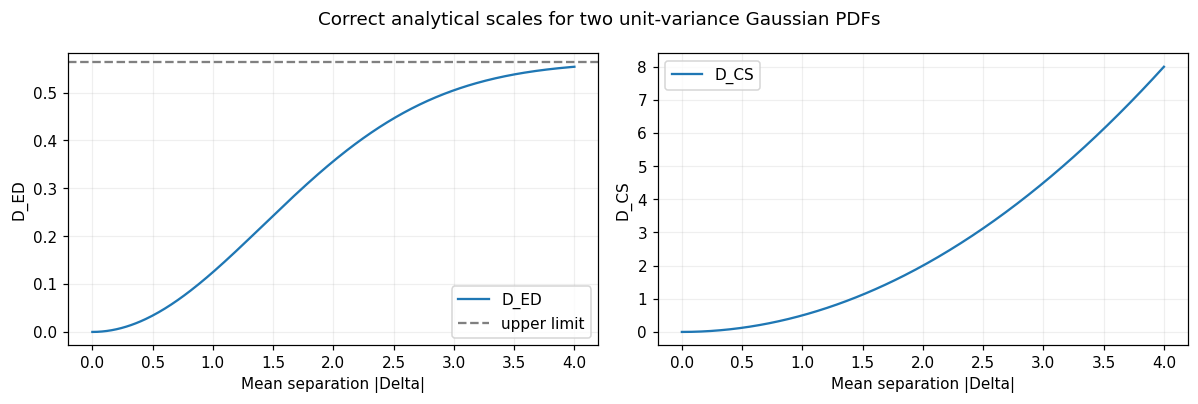

At Delta=2, D_ED= 0.3566358348374589  D_CS= 2.0


In [6]:
s=1.0
delta=np.linspace(0,4,300)
ed=(1/(np.sqrt(np.pi)*s))*(1-np.exp(-delta**2/(4*s*s)))
cs=delta**2/(2*s*s)
fig,axes=plt.subplots(1,2,figsize=(11,3.7))
axes[0].plot(delta,ed,label='D_ED')
axes[0].axhline(1/np.sqrt(np.pi),ls='--',color='gray',label='upper limit')
axes[1].plot(delta,cs,label='D_CS')
for ax in axes:
    ax.set(xlabel='Mean separation |Delta|');ax.grid(alpha=.2);ax.legend()
axes[0].set_ylabel('D_ED');axes[1].set_ylabel('D_CS')
plt.suptitle('Correct analytical scales for two unit-variance Gaussian PDFs')
plt.tight_layout();plt.show()
print('At Delta=2, D_ED=',(1/np.sqrt(np.pi))*(1-np.exp(-1)),' D_CS=',2.0)

## Experiment 5 — Quadratic mutual information for two labeled classes

We optimize the dependence between a learned 1D feature $Z=w^\top X$ and binary class label $C$.

The **Euclidean quadratic mutual information** is

$$I_{\rm ED}(Z;C)=\iint [p_{ZC}(z,c)-p_Z(z)p_C(c)]^2\,dz\,d\mu(c),$$

where $d\mu(c)$ is counting measure over class values. For the continuous feature we use Gaussian kernels, and for class labels we use the **Kronecker-delta kernel** $k_C(c_i,c_j)=\mathbf1\{c_i=c_j\}$, which is an exact categorical similarity, not a fictitious Gaussian density on integer labels.

For paired samples $(z_i,c_i)$, define $K^Z_{ij}=G_h(z_i-z_j)$ and $K^C_{ij}=\mathbf1(c_i=c_j)$. Then

$$\widehat V_J=\frac1{N^2}\sum_{ij}K^Z_{ij}K^C_{ij},$$
$$\widehat V_C=\frac1N\sum_i\left(\frac1N\sum_jK^Z_{ij}\right)\left(\frac1N\sum_jK^C_{ij}\right),$$
$$\widehat V_M=\left(\frac1{N^2}\sum_{ij}K^Z_{ij}\right)\left(\frac1{N^2}\sum_{ij}K^C_{ij}\right),$$
$$\boxed{\widehat I_{\rm ED}=\widehat V_J-2\widehat V_C+\widehat V_M.}$$

This is a **kernel plug-in estimator for the continuous--categorical density discrepancy**, using the Gaussian-convolution kernel for $Z$ and delta kernel for $C$. The objective is optimized with automatic differentiation. To prevent a trivial increase or decrease in feature scale, **constrain $\|w\|_2=1$**. We construct data whose horizontal coordinate is a nuisance and whose vertical coordinate distinguishes classes.

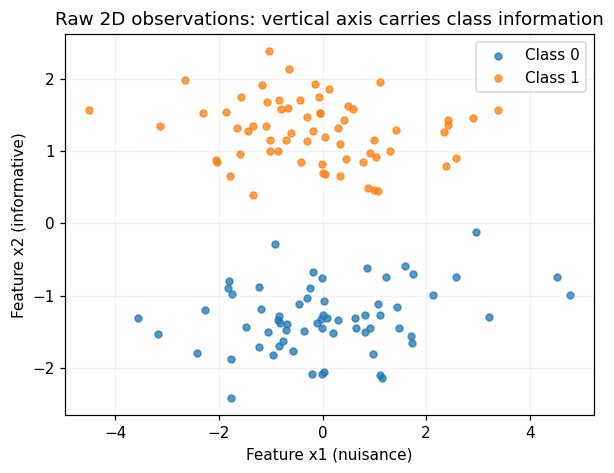

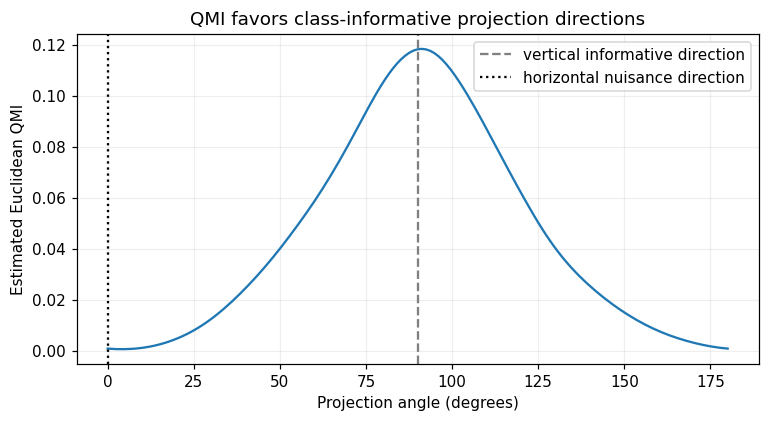

In [7]:
rng=np.random.default_rng(18)
num_each=65
cls=np.r_[np.zeros(num_each,dtype=int),np.ones(num_each,dtype=int)]
# same high-variance nuisance x for both groups; y carries the label information
noise_x=rng.normal(0,1.6,2*num_each)
label_y=np.where(cls==0,-1.25,1.25)+rng.normal(0,.42,2*num_each)
data=np.c_[noise_x,label_y]
fig,ax=plt.subplots(figsize=(6.2,4.5))
for c,name in [(0,'Class 0'),(1,'Class 1')]:
    ax.scatter(*data[cls==c].T,s=20,alpha=.75,label=name)
ax.set(title='Raw 2D observations: vertical axis carries class information',xlabel='Feature x1 (nuisance)',ylabel='Feature x2 (informative)')
ax.legend();ax.grid(alpha=.15);plt.show()

T=torch.tensor(data,dtype=torch.float64)
labels=torch.tensor(cls)
Kc=(labels[:,None]==labels[None,:]).to(dtype=torch.float64)

def qmi_ed_torch(z,Kc,h=.55):
    """Quadratic Euclidean MI with Gaussian feature kernel and delta label kernel."""
    z=z.reshape(-1,1)
    Kz=pair_kernel_torch(z,z,h)
    Vj=(Kz*Kc).mean()
    Vc=(Kz.mean(dim=1)*Kc.mean(dim=1)).mean()
    Vm=Kz.mean()*Kc.mean()
    return Vj-2*Vc+Vm

def qmi_for_angle(theta):
    w=torch.stack([torch.cos(theta),torch.sin(theta)])
    return qmi_ed_torch(T@w,Kc,.55)

# Plot objective over all 1D projection directions
angles=np.linspace(0,np.pi,151)
score=[]
with torch.no_grad():
    for a in angles:
        score.append(float(qmi_for_angle(torch.tensor(a))))
score=np.asarray(score)
fig,ax=plt.subplots(figsize=(8,3.9))
ax.plot(angles*180/np.pi,score)
ax.axvline(90,color='gray',ls='--',label='vertical informative direction')
ax.axvline(0,color='black',ls=':',label='horizontal nuisance direction')
ax.set(xlabel='Projection angle (degrees)',ylabel='Estimated Euclidean QMI',title='QMI favors class-informative projection directions')
ax.legend();ax.grid(alpha=.2);plt.show()

Initial angle (degrees): 24.064227395494573
Learned angle (degrees): 91.12173921602428
Initial QMI: 0.0073807479743243365 Final QMI: 0.11834691831719209


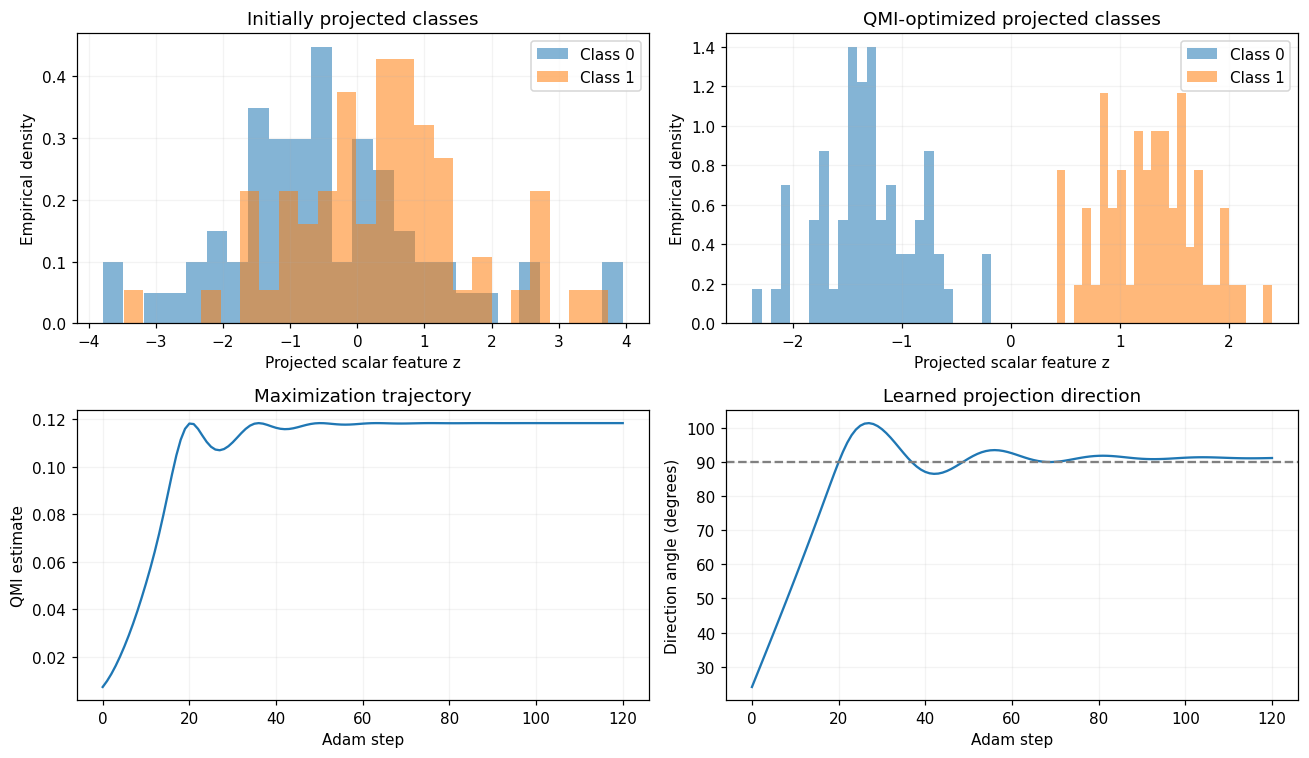

Autograd dQMI/dtheta: 0.0828095998302168
Numerical dQMI/dtheta: 0.08280959982870373


In [8]:
# Learn projection angle (rather than directly learning w) to enforce |w|=1 exactly.
theta=torch.tensor(0.42,dtype=torch.float64,requires_grad=True)
optimizer=torch.optim.Adam([theta],lr=.055)
qmi_history=[]; theta_history=[]
for step in range(121):
    optimizer.zero_grad()
    objective=qmi_for_angle(theta)
    qmi_history.append(float(objective.detach()))
    theta_history.append(float(theta.detach()))
    if step<120:
        (-objective).backward()  # maximize QMI
        optimizer.step()

with torch.no_grad():
    angle=float(theta)
    learned_w=np.array([np.cos(angle),np.sin(angle)])
    initial_w=np.array([np.cos(.42),np.sin(.42)])
    initial_z=data@initial_w
    learned_z=data@learned_w
    print('Initial angle (degrees):',.42*180/np.pi)
    print('Learned angle (degrees):',angle*180/np.pi)
    print('Initial QMI:',qmi_history[0], 'Final QMI:',qmi_history[-1])

fig,axes=plt.subplots(2,2,figsize=(12,7))
for ax,z,title in [(axes[0,0],initial_z,'Initially projected classes'),(axes[0,1],learned_z,'QMI-optimized projected classes')]:
    for c in [0,1]:
        ax.hist(z[cls==c],bins=25,alpha=.55,density=True,label=f'Class {c}')
    ax.set(title=title,xlabel='Projected scalar feature z',ylabel='Empirical density')
    ax.legend()
axes[1,0].plot(qmi_history)
axes[1,0].set(xlabel='Adam step',ylabel='QMI estimate',title='Maximization trajectory')
axes[1,1].plot(np.asarray(theta_history)*180/np.pi)
axes[1,1].axhline(90,color='gray',ls='--')
axes[1,1].set(xlabel='Adam step',ylabel='Direction angle (degrees)',title='Learned projection direction')
for ax in axes.ravel():ax.grid(alpha=.15)
plt.tight_layout();plt.show()

# Finite-difference check for QMI parameter gradient
at=torch.tensor(.73,dtype=torch.float64,requires_grad=True)
q=qmi_for_angle(at)
q.backward()
eps=1e-5
with torch.no_grad():
    finite=(qmi_for_angle(torch.tensor(.73+eps,dtype=torch.float64))-qmi_for_angle(torch.tensor(.73-eps,dtype=torch.float64)))/(2*eps)
print('Autograd dQMI/dtheta:',at.grad.item())
print('Numerical dQMI/dtheta:',float(finite))
assert np.isclose(at.grad.item(),float(finite),rtol=1e-5,atol=1e-6)

## Extra: relationship to Cauchy–Schwarz quadratic mutual information

The same three potentials define the Cauchy–Schwarz version:

$$I_{\rm CS}(Z;C)=\log V_J+\log V_M-2\log V_C.$$

The logarithm requires positive quantities (which hold for the Gaussian-feature/delta-label estimator here when both classes have observations). In the optimization problem, Euclidean QMI and Cauchy–Schwarz QMI are **different objectives**, so they need not select exactly the same projection under all data or kernel choices.

In [9]:
def qmi_cs_torch(z,Kc,h=.55):
    z=z.reshape(-1,1)
    Kz=pair_kernel_torch(z,z,h)
    Vj=(Kz*Kc).mean()
    Vc=(Kz.mean(1)*Kc.mean(1)).mean()
    Vm=Kz.mean()*Kc.mean()
    return torch.log(Vj)+torch.log(Vm)-2*torch.log(Vc)
with torch.no_grad():
    for name,w in [('initial',initial_w),('learned',learned_w)]:
        z=T@torch.tensor(w,dtype=torch.float64)
        print(f'{name:>7}: I_ED={qmi_ed_torch(z,Kc):.5f}; I_CS={qmi_cs_torch(z,Kc):.5f}')

initial: I_ED=0.00738; I_CS=0.07344
learned: I_ED=0.11835; I_CS=0.68544


## Summary: which derivative acts on which object?

| Quantity | Mathematical expression | Meaning |
|:--|:--|:--|
| Kernel field | $\Phi(x)=N^{-1}\sum_iG_h(x-x_i)$ | Local potential at a query location |
| Local information force | $\nabla_x\Phi(x)$ | Moves a query uphill in the **fixed** field |
| Global information potential | $V_2=N^{-2}\sum_{ij}G_h(x_i-x_j)$ | Overall concentration of the sample distribution |
| Global particle derivative | $\nabla_{x_k}V_2=(2/N)\nabla_x\Phi(x)|_{x=x_k}$ | Includes both occurrences of the moving particle in the pair sum |
| Quadratic entropy derivative | $\nabla_{x_k}H_2=-\nabla_{x_k}V_2/V_2$ | Pushes opposite to the IP gradient |
| Model derivative | $\nabla_\theta J=\sum_i(\partial y_i/\partial\theta)^T\nabla_{y_i}J$ | Backpropagates information forces into model parameters |
| Distribution divergence | $D_{\rm ED}=V_p+V_q-2V_c$ | Within-distribution and cross-distribution forces |
| Quadratic MI | $I_{\rm ED}=V_J-2V_C+V_M$ | Dependence between features and labels |

**Limitations and reproducibility.** The estimators in this notebook use biased all-pairs $V$-statistics, including self-interactions, and fixed kernel bandwidths. Optimization of moving particles or projected features is not equivalent to model-free inference about real data distributions. Change the random seeds, bandwidths, dataset size, and starting projection angles to evaluate sensitivity. Every example is intentionally small enough to run on Colab CPU.

**Reference:** José C. Principe, *Information Theoretic Learning: Rényi's Entropy and Kernel Perspectives*. Springer, 2010. DOI: 10.1007/978-1-4419-1570-2.